In [5]:
import os
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
from entsoe import EntsoePandasClient

api_key = subprocess.run(
    ["security", "find-generic-password", "-a", os.environ["USER"], "-s", "wind_de", "-w"],
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()
client = EntsoePandasClient(api_key=api_key)

ZONES = {
    "50Hertz": "DE_50HZ",
    "Amprion": "DE_AMPRION",
    "TenneT": "DE_TENNET",
    "TransnetBW": "DE_TRANSNET",
}

In [6]:
start = pd.Timestamp("2026-01-01", tz="Europe/Berlin")
end = pd.Timestamp("2026-12-31", tz="Europe/Berlin")

rows = []
for zone, code in ZONES.items():
    try:
        cap = client.query_installed_generation_capacity(code, start=start, end=end)
        first = cap.iloc[0]
        rows.append(
            {
                "zone": zone,
                "onshore": first.get("Wind Onshore"),
                "offshore": first.get("Wind Offshore"),
            }
        )
    except Exception as e:
        print(zone, "->", e)

entsoe_gw = pd.DataFrame(rows).set_index("zone") / 1000
entsoe_gw

,onshore,offshore
zone,,
50Hertz,22.62900,1.82800
Amprion,13.93900,NaN
TenneT,28.96023,7.39842
TransnetBW,2.16470,NaN


In [9]:
z = pd.read_parquet("../data/interim/turbines_stage1.parquet")
ref = pd.Timestamp("2026-01-01")

active = z[
    (z["commissioned"] <= ref)
    & (z["decommissioned"].isna() | (z["decommissioned"] > ref))
    & z["zone"].notna()
]
mastr_gw = active.groupby(["zone", "location_type"])["capacity_kw"].sum().unstack() / 1e6

compare = pd.DataFrame(
    {
        "onshore_mastr": mastr_gw["onshore"],
        "onshore_entsoe": entsoe_gw["onshore"],
        "offshore_mastr": mastr_gw.get("offshore"),
        "offshore_entsoe": entsoe_gw["offshore"],
    }
)
compare["onshore_diff_%"] = 100 * (compare["onshore_mastr"] / compare["onshore_entsoe"] - 1)
compare["offshore_diff_%"] = 100 * (compare["offshore_mastr"] / compare["offshore_entsoe"] - 1)
compare.round(2)

,onshore_mastr,onshore_entsoe,offshore_mastr,offshore_entsoe,onshore_diff_%,offshore_diff_%
zone,,,,,,
50Hertz,22.71,22.63,1.83,1.83,0.35,0.01
Amprion,14.80,13.94,NaN,NaN,6.20,NaN
TenneT,28.50,28.96,7.91,7.40,-1.58,6.85
TransnetBW,2.08,2.16,NaN,NaN,-3.96,NaN


Text(0, 0.5, 'Latitude')

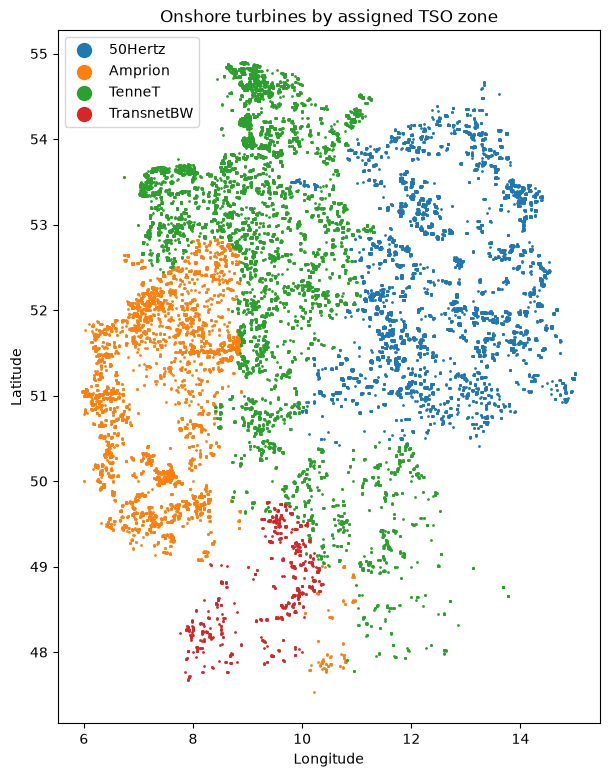

In [10]:
onshore = z[z["location_type"] == "onshore"]
plt.figure(figsize=(7, 9))
for zone, d in onshore.groupby("zone"):
    plt.scatter(d["lon"], d["lat"], s=1, label=zone)
plt.legend(markerscale=10)
plt.title("Onshore turbines by assigned TSO zone")
plt.xlabel("Longitude")
plt.ylabel("Latitude")